# Analyse exploratoire des données

Explorer les exercices, leurs annotations et leurs descriptions.

## 1. Vue d’ensemble des exercices 

Charger les JSON bruts et distinguer les exercices annotés, les annotations vides et les exercices sans tag cible. 


In [1]:
from difflib import SequenceMatcher
from pathlib import Path
import html
import json
import re
import unicodedata

from matplotlib.colors import LinearSegmentedColormap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

dossier = Path("code_classification_dataset")
if not dossier.is_dir():
    dossier = Path("..") / dossier
fichiers = sorted(dossier.glob("*.json"))
if not fichiers:
    raise FileNotFoundError("Aucun JSON trouvé dans code_classification_dataset/.")

donnees = pd.DataFrame([json.loads(fichier.read_text(encoding="utf-8")) for fichier in fichiers])
noms_fichiers = [fichier.name for fichier in fichiers]
nombre_exercices = len(donnees)
tags_cibles = ["math", "graphs", "strings", "number theory", "trees", "geometry", "games", "probabilities"]
ensembles_tags = donnees["tags"].map(set)
tags_existants = sorted(set().union(*ensembles_tags))
etiquettes = pd.DataFrame({tag: ensembles_tags.map(lambda tags: int(tag in tags)) for tag in tags_cibles})
nombre_cibles = etiquettes.sum(axis=1)
annotations_vides = ensembles_tags.map(len).eq(0)
sans_cible = nombre_cibles.eq(0)
autres_tags_uniquement = sans_cible & ~annotations_vides

plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})


def formater_nombre(nombre):
    return f"{int(nombre):,}".replace(",", " ")

In [2]:
resume = pd.Series({
    "Nombre total d’exercices": nombre_exercices,
    "Nombre de tags distincts": len(tags_existants),
    "Nombre de tags cibles": len(tags_cibles),
    "Exercices avec au moins un tag": int((~annotations_vides).sum()),
    "Exercices avec des tags répétés": int(donnees["tags"].map(len).ne(ensembles_tags.map(len)).sum()),
    "Exercices sans tag cible": int(sans_cible.sum()),
    "Exercices avec tag cible": int(nombre_cibles.ge(1).sum()),
    "Exercices sans aucun tag": int(annotations_vides.sum()),
}, name="Nombre")
display(resume.to_frame())
display(Markdown("**Tags existants :** " + ", ".join(f"`{tag}`" for tag in tags_existants) + "."))
display(Markdown("**Tags cibles :** " + ", ".join(f"`{tag}`" for tag in tags_cibles) + "."))

,Nombre
Nombre total d’exercices,4982
Nombre de tags distincts,37
Nombre de tags cibles,8
Exercices avec au moins un tag,4941
Exercices avec des tags répétés,9
Exercices sans tag cible,2304
Exercices avec tag cible,2678
Exercices sans aucun tag,41


**Tags existants :** `*special`, `2-sat`, `binary search`, `bitmasks`, `brute force`, `chinese remainder theorem`, `combinatorics`, `constructive algorithms`, `data structures`, `dfs and similar`, `divide and conquer`, `dp`, `dsu`, `expression parsing`, `fft`, `flows`, `games`, `geometry`, `graph matchings`, `graphs`, `greedy`, `hashing`, `implementation`, `interactive`, `math`, `matrices`, `meet-in-the-middle`, `number theory`, `probabilities`, `schedules`, `shortest paths`, `sortings`, `string suffix structures`, `strings`, `ternary search`, `trees`, `two pointers`.

**Tags cibles :** `math`, `graphs`, `strings`, `number theory`, `trees`, `geometry`, `games`, `probabilities`.

Une liste vide indique une absence d’annotation disponible, elle ne prouve pas qu’aucun tag serait pertinent. Un exercice annoté uniquement avec d’autres tags reste utile pour apprendre à prédire l’absence des huit cibles.

## 2. Structure et complétude des champs

Présenter tous les champs, leur type dans le DataFrame et leurs valeurs non nulles et distinctes. Les noms des champs sources sont conservés.


In [3]:
profil_champs = pd.DataFrame({
    "type_dataframe": donnees.dtypes.astype(str),
    "valeurs_non_nulles": donnees.notna().sum(),
    "valeurs_distinctes_non_nulles": donnees.apply(
        lambda colonne: colonne.dropna().map(lambda valeur: json.dumps(valeur, sort_keys=True)).nunique()
    ),
}).rename_axis("champ").reset_index()
with pd.option_context("display.max_rows", None):
    display(profil_champs)

,champ,type_dataframe,valeurs_non_nulles,valeurs_distinctes_non_nulles
0,prob_desc_time_limit,object,4982,22
1,prob_desc_sample_outputs,object,4982,4132
2,src_uid,object,4982,4982
3,prob_desc_notes,object,3632,3596
4,prob_desc_description,object,4982,4982
5,prob_desc_output_spec,object,4897,4821
6,prob_desc_input_spec,object,4949,4927
7,prob_desc_output_to,object,4981,3
8,prob_desc_input_from,object,4981,3
9,lang,object,4982,5


## 3. Fréquence des tags cibles 

Les huit premières barres indiquent la présence de chaque cible, tandis que la catégorie correspondant aux autres tags désigne les exercices annotés qui ne portent aucune des huit cibles, et celle correspondant aux exercices sans annotations désigne les listes vides. Les pourcentages sont calculés sur tous les exercices, les cibles peuvent donc se chevaucher et leurs pourcentages ne constituent pas une partition à 100%.


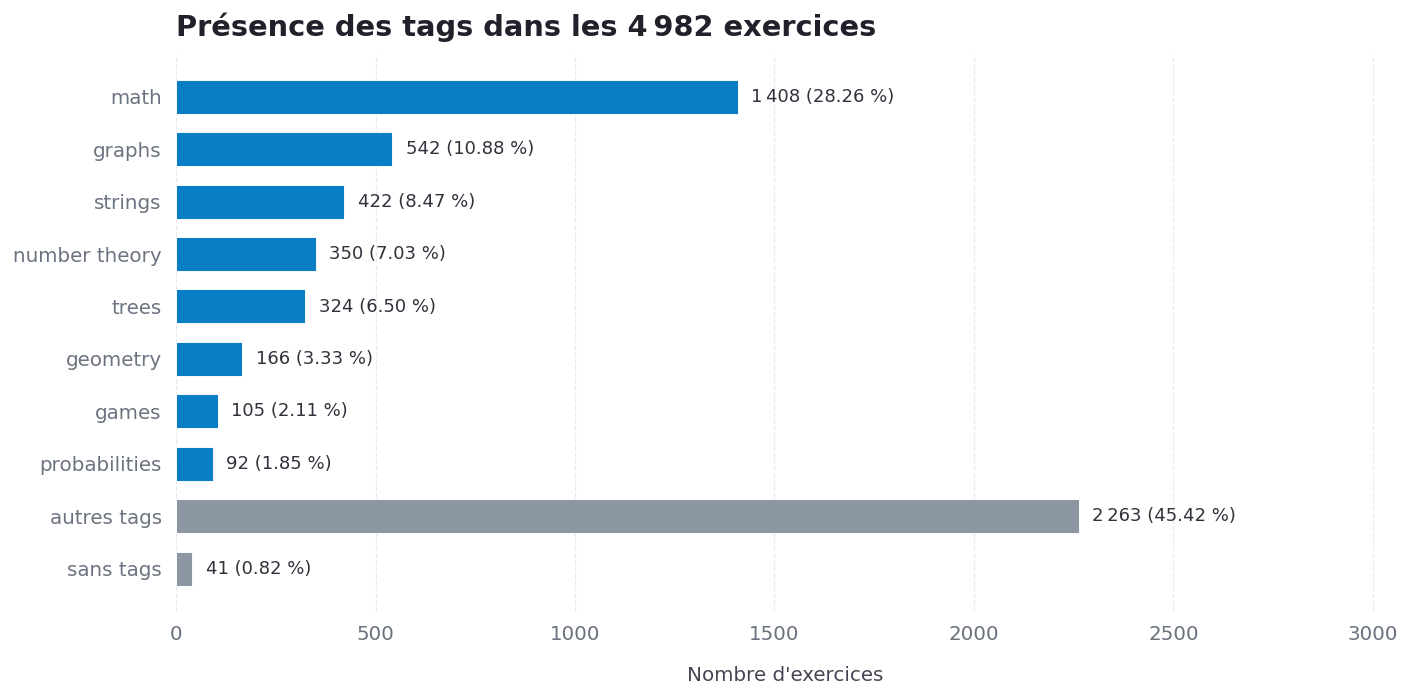

,categorie,nombre_exercices,pourcentage
0,math,1408,28.26
1,graphs,542,10.88
2,strings,422,8.47
3,number theory,350,7.03
4,trees,324,6.50
5,geometry,166,3.33
6,games,105,2.11
7,probabilities,92,1.85
8,autres tags,2263,45.42
9,sans tags,41,0.82


In [4]:
frequences = pd.DataFrame({
    "categorie": tags_cibles + ["autres tags", "sans tags"],
    "nombre_exercices": [int(etiquettes[tag].sum()) for tag in tags_cibles]
                         + [int(autres_tags_uniquement.sum()), int(annotations_vides.sum())],
})
frequences["pourcentage"] = 100 * frequences["nombre_exercices"] / nombre_exercices

colors = ["#087FC4"] * len(tags_cibles) + ["#8D96A3", "#8D96A3"]

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

fig, ax = plt.subplots(figsize=(11, 5.5), dpi=130)
barres = ax.barh(
    frequences["categorie"], frequences["nombre_exercices"],
    color=colors, height=0.65, edgecolor="white", linewidth=0.5, zorder=3
)

ax.invert_yaxis()
ax.set_xlim(0, frequences["nombre_exercices"].max() * 1.35)
ax.set_xlabel("Nombre d'exercices", labelpad=12, color="#454654")
ax.set_title(
    f"Présence des tags dans les {formater_nombre(nombre_exercices)} exercices",
    loc="left", pad=10, color="#20212A"
)

ax.tick_params(axis="both", length=0, pad=8, colors="#6B7280")
ax.set_axisbelow(True)
ax.grid(axis="x", linestyle="--", linewidth=0.7, color="#E5E7EB", alpha=0.9)

for spine in ["top", "right", "left", "bottom"]:
    ax.spines[spine].set_visible(False)

for barre, ligne in zip(barres, frequences.itertuples(index=False)):
    ax.text(
        barre.get_width() + frequences["nombre_exercices"].max() * 0.015,
        barre.get_y() + barre.get_height() / 2,
        f"{formater_nombre(ligne.nombre_exercices)} ({ligne.pourcentage:.2f} %)",
        va="center", fontsize=10, color="#30313B", fontweight="medium"
    )

plt.tight_layout()
plt.show()

display(frequences.round({"pourcentage": 2}))

## 4. Nombre de tags cibles par exercice

Compter les cibles distinctes de chaque exercice. Les cas avec au moins deux cibles établissent le caractère **multi-étiquette** du problème ; une sortie sans tag cible doit également rester possible.


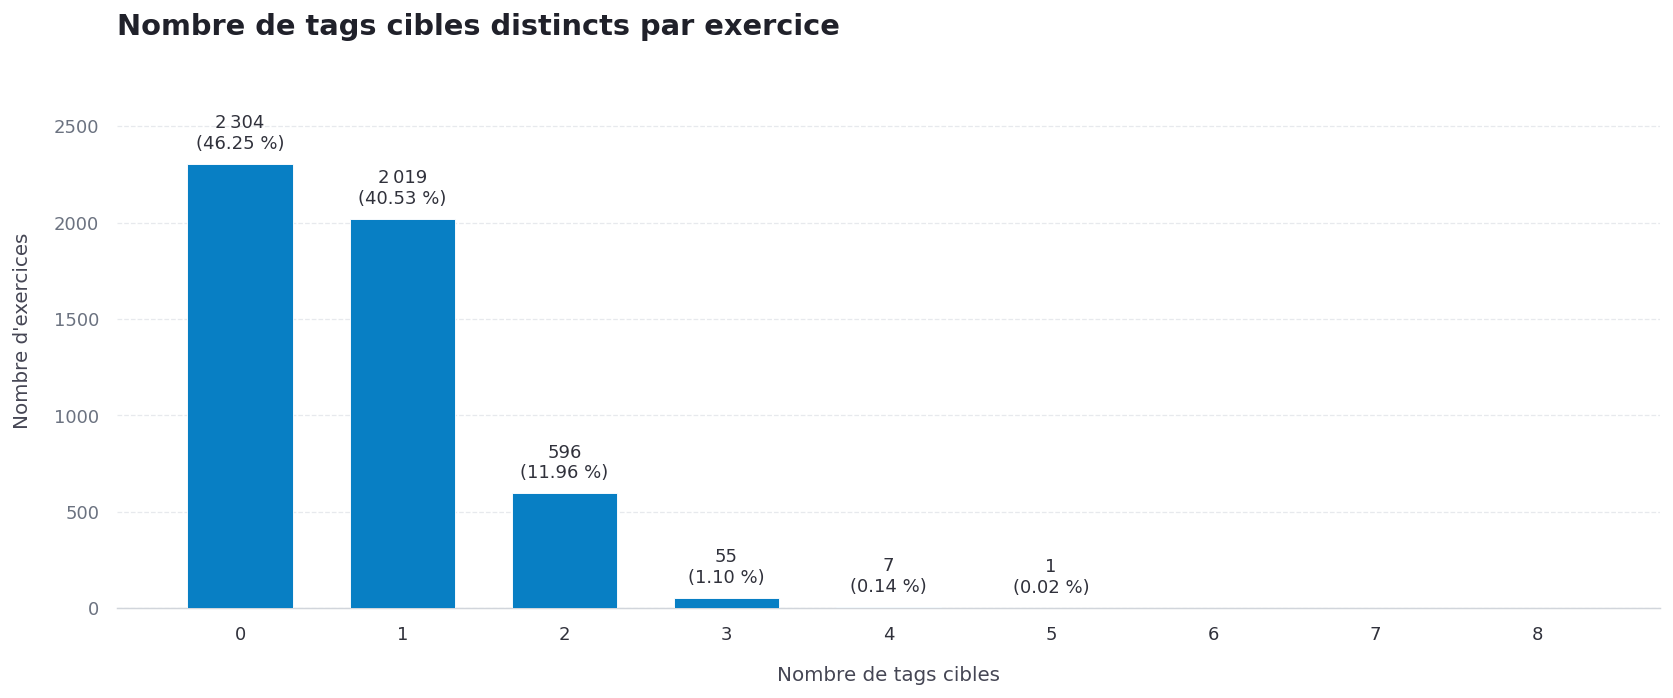

In [5]:
distribution = nombre_cibles.value_counts().reindex(range(9), fill_value=0).sort_index()

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

fig, ax = plt.subplots(figsize=(13, 5.5), dpi=130)
barres = ax.bar(
    distribution.index, distribution.values,
    color="#087FC4", width=0.65,
    edgecolor="white", linewidth=0.5, zorder=3
)

ax.set_xticks(range(9))
ax.set_ylim(0, distribution.max() * 1.25)
ax.set_xlabel("Nombre de tags cibles", labelpad=12, color="#454654")
ax.set_ylabel("Nombre d'exercices", labelpad=12, color="#454654")
ax.set_title(
    "Nombre de tags cibles distincts par exercice",
    loc="left", pad=10, color="#20212A"
)

ax.tick_params(axis="both", labelsize=10, length=0, pad=10, colors="#6B7280")
plt.setp(ax.get_xticklabels(), color="#30313B")

ax.set_axisbelow(True)
ax.grid(axis="y", linestyle="--", linewidth=0.7, color="#E5E7EB", alpha=0.9)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.spines["bottom"].set_color("#D1D5DB")
ax.spines["bottom"].set_linewidth(0.8)

for nombre_tags, effectif in distribution.items():
    if effectif:
        ax.text(
            nombre_tags, effectif + distribution.max() * 0.025,
            f"{formater_nombre(effectif)}\n({100 * effectif / nombre_exercices:.2f} %)",
            ha="center", va="bottom", fontsize=10,
            color="#30313B", fontweight="medium"
        )

plt.tight_layout()
plt.show()

## 5. Associations conditionnelles entre tags cibles

Dans la matrice, ligne A, colonne B = P(B | A) = nombre(A et B) / nombre(A). La cellule transposée donne P(A | B). 


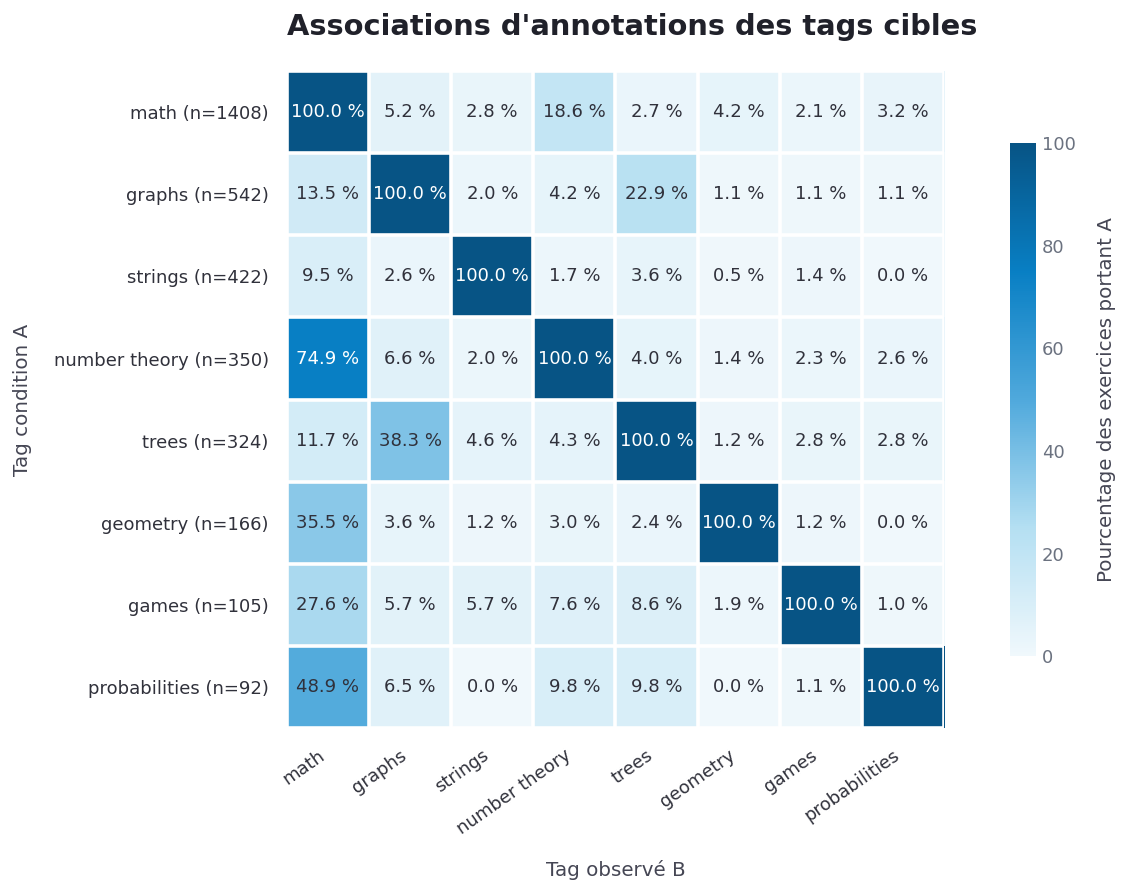

,association,pourcentage
0,P(number theory | math),18.61
1,P(math | number theory),74.86


In [6]:
cooccurrences = etiquettes.T.dot(etiquettes)
conditionnelles = 100 * cooccurrences.div(etiquettes.sum().replace(0, np.nan), axis=0)

cmap = LinearSegmentedColormap.from_list(
    "illuin_blue", ["#F0F8FC", "#B4DFF2", "#50A9DC", "#087FC4", "#075485"]
)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

fig, ax = plt.subplots(figsize=(13, 7), dpi=130)
image = ax.imshow(conditionnelles, cmap=cmap, vmin=0, vmax=100, aspect="equal")

ax.set_xticks(range(len(tags_cibles)), tags_cibles, rotation=35, ha="right")
ax.set_yticks(
    range(len(tags_cibles)),
    [f"{tag} (n={etiquettes[tag].sum()})" for tag in tags_cibles]
)

ax.set_xlabel("Tag observé B", labelpad=12, color="#454654")
ax.set_ylabel("Tag condition A", labelpad=12, color="#454654")
ax.set_title(
    "Associations d'annotations des tags cibles",
    loc="left", pad=20, color="#20212A"
)

ax.tick_params(axis="both", labelsize=10, length=0, pad=10, colors="#6B7280")
plt.setp(ax.get_xticklabels(), color="#30313B")
plt.setp(ax.get_yticklabels(), color="#30313B")

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xticks(np.arange(-0.5, len(tags_cibles), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(tags_cibles), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.tick_params(which="minor", bottom=False, left=False)

for i in range(len(tags_cibles)):
    for j in range(len(tags_cibles)):
        valeur = conditionnelles.iloc[i, j]
        ax.text(
            j, i, f"{valeur:.1f} %" if pd.notna(valeur) else "n.d.",
            ha="center", va="center", fontsize=10,
            color="white" if valeur > 55 else "#30313B",
            fontweight="medium"
        )

cbar = fig.colorbar(image, ax=ax, shrink=0.78, pad=0.04)
cbar.set_label("Pourcentage des exercices portant A", labelpad=12, color="#454654")
cbar.ax.tick_params(labelsize=10, length=0, colors="#6B7280")
cbar.outline.set_visible(False)

plt.tight_layout()
plt.show()

comparaison = pd.DataFrame({
    "association": ["P(number theory | math)", "P(math | number theory)"],
    "pourcentage": [
        conditionnelles.loc["math", "number theory"],
        conditionnelles.loc["number theory", "math"]
    ],
})
display(comparaison.round({"pourcentage": 2}))

P(B | A) n'est généralement pas égal à P(A | B). Ces associations d'annotations ne justifient donc pas d'imposer automatiquement un tag à partir d'un autre. 

## 6. Exemples avec des descriptions proches

Commencer par rechercher les exemples ayant des descriptions identiques, puis comparer toutes les paires selon deux mesures complémentaires :

- **Cosinus :** proximité de vecteurs TF-IDF construits sur les mots et paires de mots, les termes sont pondérés par leur importance dans le corpus.
- **Jaccard :** proportion de mots distincts partagés (`nombre de mots communs / nombre de mots dans l’union`), la fréquence et l’ordre des mots ne sont pas pris en compte.

Les deux scores sont compris entre 0 et 1. La normalisation ignore la casse et les espaces, décode les entités HTML et normalise Unicode. La tokenisation conserve les mots d’un caractère et les nombres, mais ignore les opérateurs et la ponctuation : un score de 1 ne prouve donc pas l’équivalence des exercices.


In [7]:
def normaliser_description(description):
    description = unicodedata.normalize("NFC", html.unescape(description)).casefold()
    return re.sub(r"\s+", " ", description).strip()


descriptions = donnees["prob_desc_description"].fillna("").map(normaliser_description)
controle_doublons = []
for libelle, valeurs in {"Description brute": donnees["prob_desc_description"],
                        "Description normalisée": descriptions}.items():
    effectifs = valeurs.dropna().loc[lambda serie: serie.str.strip().ne("")].value_counts()
    controle_doublons.append({"controle": libelle, "groupes_identiques": int(effectifs.gt(1).sum()),
                              "exemplaires_en_trop": int((effectifs - 1).sum())})
display(pd.DataFrame(controle_doublons))

seuil_cosinus = 0.80
seuil_jaccard = 0.80
seuils_comparaison = [0.50, 0.70, 0.80, 0.90, 0.95]
seuil_conservation = min(seuils_comparaison + [seuil_cosinus, seuil_jaccard])

parametres_mots = {"lowercase": False, "token_pattern": r"(?u)\b\w+\b"}
vecteurs_tfidf = TfidfVectorizer(**parametres_mots, ngram_range=(1, 2), sublinear_tf=True).fit_transform(descriptions)

presence_mots = CountVectorizer(**parametres_mots, binary=True, dtype=np.int32).fit_transform(descriptions)
tailles_vocabulaire = np.asarray(presence_mots.sum(axis=1)).ravel()
if (tailles_vocabulaire == 0).any():
    raise ValueError("Une description est vide après tokenisation ; l’examiner avant de poursuivre.")

,controle,groupes_identiques,exemplaires_en_trop
0,Description brute,0,0
1,Description normalisée,0,0


Seules les paires dont le cosinus ou le Jaccard atteint le seuil minimal de 0,50 sont enregistrées. Ce filtrage conserve toutes les paires nécessaires au décompte des seuils étudiés, qui sont tous supérieurs ou égaux à 0,50.


In [8]:
lignes_paires = []
nombre_paires_comparees = 0
indices = np.arange(nombre_exercices)
for debut in range(0, nombre_exercices, 256):
    fin = min(debut + 256, nombre_exercices)
    cosinus = (vecteurs_tfidf[debut:fin] @ vecteurs_tfidf.T).toarray()
    np.clip(cosinus, 0, 1, out=cosinus)
    intersections = (presence_mots[debut:fin] @ presence_mots.T).toarray()
    unions = tailles_vocabulaire[debut:fin, None] + tailles_vocabulaire[None, :] - intersections
    jaccard = intersections / unions
    triangle_superieur = indices[debut:fin, None] < indices[None, :]
    nombre_paires_comparees += int(triangle_superieur.sum())
    a_conserver = triangle_superieur & ((cosinus >= seuil_conservation) | (jaccard >= seuil_conservation))
    lignes, colonnes = np.where(a_conserver)
    lignes_paires.extend((debut + int(i), int(j), float(cosinus[i, j]), float(jaccard[i, j]))
                         for i, j in zip(lignes, colonnes))

assert nombre_paires_comparees == nombre_exercices * (nombre_exercices - 1) // 2
paires = pd.DataFrame(lignes_paires, columns=["indice_A", "indice_B", "cosinus", "jaccard"])
paires = paires.sort_values(["cosinus", "jaccard", "indice_A", "indice_B"],
                            ascending=[False, False, True, True]).reset_index(drop=True)
paires["fichier_A"] = paires["indice_A"].map(lambda indice: noms_fichiers[indice])
paires["fichier_B"] = paires["indice_B"].map(lambda indice: noms_fichiers[indice])

bilan_seuils = pd.DataFrame([{
    "seuil": seuil,
    "paires_cosinus": int(paires["cosinus"].ge(seuil).sum()),
    "paires_jaccard": int(paires["jaccard"].ge(seuil).sum()),
    "paires_avec_les_deux": int((paires["cosinus"].ge(seuil) & paires["jaccard"].ge(seuil)).sum()),
} for seuil in seuils_comparaison])
display(bilan_seuils)

,seuil,paires_cosinus,paires_jaccard,paires_avec_les_deux
0,0.50,131,133,106
1,0.70,83,81,78
2,0.80,74,71,70
3,0.90,64,65,64
4,0.95,50,42,39


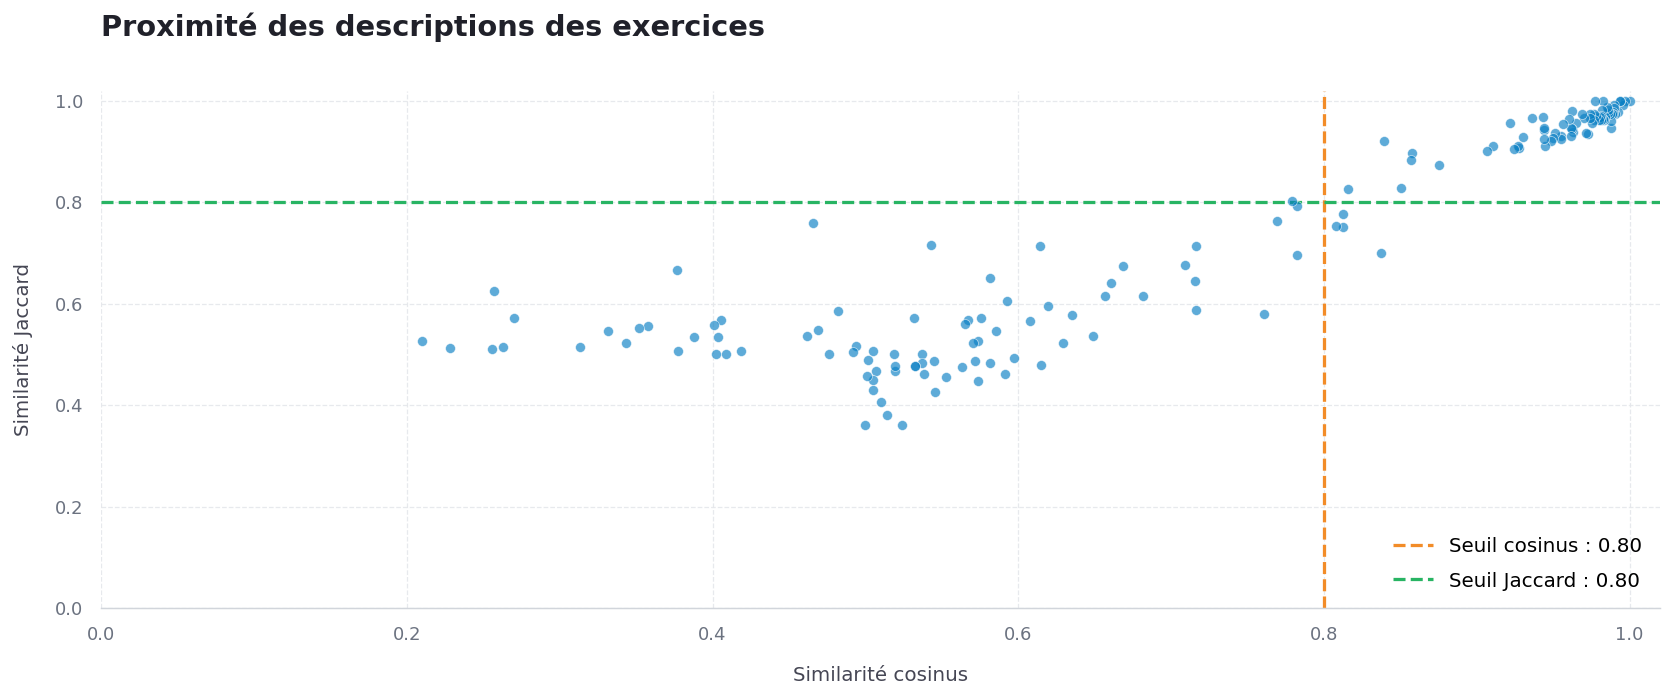

In [9]:
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

fig, ax = plt.subplots(figsize=(13, 5.5), dpi=130)

ax.scatter(
    paires["cosinus"], paires["jaccard"],
    s=30, alpha=0.65, color="#087FC4",
    edgecolors="white", linewidth=0.4, zorder=3
)

ax.axvline(
    seuil_cosinus, color="#F28C28", linewidth=1.8,
    linestyle="--", label=f"Seuil cosinus : {seuil_cosinus:.2f}"
)
ax.axhline(
    seuil_jaccard, color="#28B463", linewidth=1.8,
    linestyle="--", label=f"Seuil Jaccard : {seuil_jaccard:.2f}"
)

ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Similarité cosinus", labelpad=12, color="#454654")
ax.set_ylabel("Similarité Jaccard", labelpad=12, color="#454654")
ax.set_title(
    "Proximité des descriptions des exercices",
    loc="left", pad=30, color="#20212A"
)

ax.tick_params(axis="both", labelsize=10, length=0, pad=10, colors="#6B7280")
ax.set_axisbelow(True)
ax.grid(axis="both", linestyle="--", linewidth=0.7, color="#E5E7EB", alpha=0.9)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.spines["bottom"].set_color("#D1D5DB")
ax.spines["bottom"].set_linewidth(0.8)

ax.legend(
    loc="lower right", frameon=False,
    fontsize=11, handlelength=2, labelspacing=0.8
)

plt.tight_layout()
plt.show()

Chaque point représente une paire conservée. À droite de la ligne verticale, le cosinus atteint son seuil, au-dessus de la ligne horizontale, Jaccard atteint le sien. Le quadrant supérieur droit regroupe les paires retenues par les deux mesures. 

In [10]:
def differences_entre_textes(texte_a, texte_b):
    mots_a, mots_b = texte_a.split(), texte_b.split()
    differences = []
    for operation, a, b, c, d in SequenceMatcher(None, mots_a, mots_b, autojunk=False).get_opcodes():
        if operation != "equal":
            extrait_a = " ".join(mots_a[a:b]) or "∅"
            extrait_b = " ".join(mots_b[c:d]) or "∅"
            differences.append(f"{extrait_a} → {extrait_b}")
    return " ; ".join(differences)


paires_a_examiner = paires.loc[paires["cosinus"].ge(seuil_cosinus) | paires["jaccard"].ge(seuil_jaccard)].copy()
apercu_paires = paires_a_examiner.head(15).copy()
apercu_paires["differences_A_vers_B"] = [
    differences_entre_textes(donnees.loc[ligne.indice_A, "prob_desc_description"],
                            donnees.loc[ligne.indice_B, "prob_desc_description"])
    for ligne in apercu_paires.itertuples(index=False)
]
with pd.option_context("display.max_colwidth", 150, "display.max_rows", 15, "display.max_columns", None):
    display(apercu_paires[["fichier_A", "fichier_B", "cosinus", "jaccard", "differences_A_vers_B"]].round(4))

,fichier_A,fichier_B,cosinus,jaccard,differences_A_vers_B
0,sample_4810.json,sample_4812.json,1.0000,1.0000,$$$2$$$ → $$$3$$$ ; $$$3$$$ → $$$2$$$
1,sample_4772.json,sample_4773.json,0.9968,1.0000,hard → easy
2,sample_2839.json,sample_401.json,0.9954,0.9925,hard → easy
3,sample_3932.json,sample_3933.json,0.9940,1.0000,hard → easy
4,sample_4048.json,sample_4049.json,0.9936,1.0000,an easy → a hard
5,sample_4246.json,sample_4247.json,0.9922,0.9775,hard → easy
6,sample_4351.json,sample_4352.json,0.9903,0.9737,easy → hard
7,sample_3862.json,sample_3863.json,0.9899,0.9914,(which is initially a palindrome in this version) → ∅
8,sample_2651.json,sample_2665.json,0.9897,0.9861,$$$n+1$$$ → $$$n+2$$$
9,sample_4138.json,sample_4141.json,0.9894,0.9786,hard → easy ; $$$1 \le n \le 300$$$.In → $$$n = 1$$$.In


Des descriptions presque identiques peuvent correspondre à des versions facile/difficile ou à des coûts différents. Il faut lire leurs contraintes et leurs objectifs avant de conclure à un doublon.